In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, ConfusionMatrixDisplay)
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import joblib

BASE_DIR = Path(r"C:\Projects\cancer-classifier")
PROC_DIR = BASE_DIR / "data" / "processed"
FIG_DIR  = BASE_DIR / "outputs" / "figures"
MOD_DIR  = BASE_DIR / "outputs" / "models"

# Load the cleaned, scaled dataset we built 
df    = pd.read_parquet(PROC_DIR / "dataset_scaled.parquet")
genes = pd.read_csv(PROC_DIR / "selected_genes.csv").iloc[:, 0].tolist()


X = df[genes].values                  
y = df["cancer_type"].values          

print(f"Feature matrix X: {X.shape}")
print(f"Labels y: {y.shape}")
print(f"Classes: {np.unique(y)}")

Feature matrix X: (792, 340)
Labels y: (792,)
Classes: ['BRCA' 'COAD' 'KIRC' 'LGG' 'LUAD']


In [3]:
# BRCA→0, COAD→1, KIRC→2, LGG→3, LUAD→4
le      = LabelEncoder()
y_enc   = le.fit_transform(y)
classes = le.classes_           # ['BRCA', 'COAD', 'KIRC', 'LGG', 'LUAD']
print("Label encoding:", dict(zip(classes, le.transform(classes))))

# Split into train (80%) and test (20%)
# stratify=y_enc ensures each cancer type is proportionally represented
# in BOTH train and test — critical with imbalanced classes like ours
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc,
    test_size=0.2,
    random_state=42,        # always set this — makes results reproducible
    stratify=y_enc
)

print(f"\nTraining set : {X_train.shape[0]} samples")
print(f"Test set     : {X_test.shape[0]} samples")
print(f"\nClass distribution in training set:")
for i, cls in enumerate(classes):
    print(f"  {cls}: {(y_train == i).sum()} samples")

Label encoding: {'BRCA': np.int64(0), 'COAD': np.int64(1), 'KIRC': np.int64(2), 'LGG': np.int64(3), 'LUAD': np.int64(4)}

Training set : 633 samples
Test set     : 159 samples

Class distribution in training set:
  BRCA: 159 samples
  COAD: 50 samples
  KIRC: 158 samples
  LGG: 160 samples
  LUAD: 106 samples


In [5]:
rf = RandomForestClassifier(
    n_estimators=300,      # number of trees — more = more stable but slower
    max_depth=None,        # let trees grow fully — RF handles overfitting via ensemble
    min_samples_leaf=2,    # each leaf needs at least 2 samples — light regularization
    max_features="sqrt",   # each split considers sqrt(383)≈20 genes — prevents correlation
    class_weight="balanced", # compensates for class imbalance (COAD has fewer samples)
    random_state=42,
    n_jobs=-1              # use all CPU cores
)

print("Training Random Forest...")
rf.fit(X_train, y_train)

# Evaluate on test set
rf_preds = rf.predict(X_test)
rf_acc   = accuracy_score(y_test, rf_preds)
print(f"\n Random Forest Test Accuracy: {rf_acc*100:.2f}%")

Training Random Forest...

✅ Random Forest Test Accuracy: 98.11%


In [6]:
xgb_model = xgb.XGBClassifier(
    n_estimators=300,        # number of boosting rounds
    max_depth=4,             # shallower trees than RF — boosting needs weak learners
    learning_rate=0.1,       # how much each tree corrects — lower = more robust
    subsample=0.8,           # use 80% of samples per round — reduces overfitting
    colsample_bytree=0.8,    # use 80% of genes per tree — like RF's max_features
    use_label_encoder=False,
    eval_metric="mlogloss",  # multiclass log loss — standard for classification
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],   # monitor test loss during training
    verbose=50                      # print progress every 50 rounds
)

xgb_preds = xgb_model.predict(X_test)
xgb_acc   = accuracy_score(y_test, xgb_preds)
print(f"\n XGBoost Test Accuracy: {xgb_acc*100:.2f}%")

Training XGBoost...
[0]	validation_0-mlogloss:1.32895


C:\Users\King\miniconda3\envs\cancer_clf\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:10:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[50]	validation_0-mlogloss:0.05564
[100]	validation_0-mlogloss:0.03345
[150]	validation_0-mlogloss:0.03085
[200]	validation_0-mlogloss:0.03056
[250]	validation_0-mlogloss:0.03070
[299]	validation_0-mlogloss:0.03071

 XGBoost Test Accuracy: 99.37%


In [7]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Running 5-fold cross-validation...")
print("(Each model trains 5 times — takes ~2 min)\n")

rf_cv_scores  = cross_val_score(rf,  X, y_enc, cv=cv, scoring="accuracy", n_jobs=-1)
xgb_cv_scores = cross_val_score(xgb_model, X, y_enc, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"Random Forest  CV: {rf_cv_scores.mean()*100:.2f}% ± {rf_cv_scores.std()*100:.2f}%")
print(f"XGBoost        CV: {xgb_cv_scores.mean()*100:.2f}% ± {xgb_cv_scores.std()*100:.2f}%")
print(f"\nFold-by-fold RF  : {[f'{s*100:.1f}%' for s in rf_cv_scores]}")
print(f"Fold-by-fold XGB : {[f'{s*100:.1f}%' for s in xgb_cv_scores]}")

Running 5-fold cross-validation...
(Each model trains 5 times — takes ~2 min)

Random Forest  CV: 99.12% ± 0.95%
XGBoost        CV: 98.86% ± 1.01%

Fold-by-fold RF  : ['98.7%', '99.4%', '100.0%', '100.0%', '97.5%']
Fold-by-fold XGB : ['98.7%', '98.1%', '100.0%', '100.0%', '97.5%']


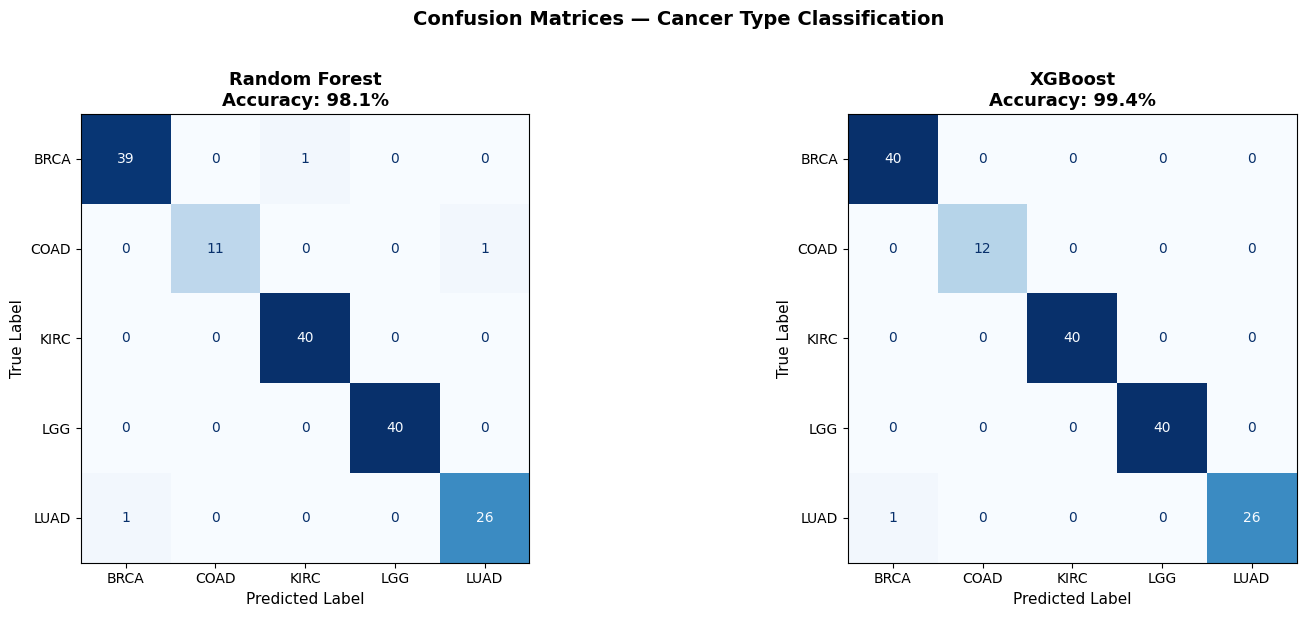

✅ Confusion matrices saved!


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, preds, title in zip(
    axes,
    [rf_preds, xgb_preds],
    ["Random Forest", "XGBoost"]
):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=classes)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{title}\nAccuracy: {accuracy_score(y_test, preds)*100:.1f}%",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)

plt.suptitle("Confusion Matrices — Cancer Type Classification",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print(" Confusion matrices saved!")

In [9]:
print("=" * 55)
print("RANDOM FOREST — Per-class Performance")
print("=" * 55)
print(classification_report(y_test, rf_preds, target_names=classes))

print("=" * 55)
print("XGBOOST — Per-class Performance")
print("=" * 55)
print(classification_report(y_test, xgb_preds, target_names=classes))

# Save both models
joblib.dump(rf,        MOD_DIR / "random_forest.joblib")
joblib.dump(xgb_model, MOD_DIR / "xgboost.joblib")
joblib.dump(le,        MOD_DIR / "label_encoder.joblib")
print("✅ Models saved to outputs/models/")

RANDOM FOREST — Per-class Performance
              precision    recall  f1-score   support

        BRCA       0.97      0.97      0.97        40
        COAD       1.00      0.92      0.96        12
        KIRC       0.98      1.00      0.99        40
         LGG       1.00      1.00      1.00        40
        LUAD       0.96      0.96      0.96        27

    accuracy                           0.98       159
   macro avg       0.98      0.97      0.98       159
weighted avg       0.98      0.98      0.98       159

XGBOOST — Per-class Performance
              precision    recall  f1-score   support

        BRCA       0.98      1.00      0.99        40
        COAD       1.00      1.00      1.00        12
        KIRC       1.00      1.00      1.00        40
         LGG       1.00      1.00      1.00        40
        LUAD       1.00      0.96      0.98        27

    accuracy                           0.99       159
   macro avg       1.00      0.99      0.99       159
weighte